In [23]:
import time
import random
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import tensorflow as tf
import shutil
import seaborn as sns
from pathlib import Path
from tensorflow.keras import layers, models, regularizers, callbacks, optimizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix,  roc_curve
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications import MobileNetV2


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.22.0-rc0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

In [6]:
dataset_path = Path("./PlantVillage")

subdirs = sorted([
    d for d in dataset_path.iterdir()
    if d.is_dir() and d.name != "PlantVillage"
])

print(f"Найдено папок классов: {len(subdirs)}")
for d in subdirs:
    print(f"  - {d.name}")

Найдено папок классов: 15
  - Pepper__bell___Bacterial_spot
  - Pepper__bell___healthy
  - Potato___Early_blight
  - Potato___Late_blight
  - Potato___healthy
  - Tomato_Bacterial_spot
  - Tomato_Early_blight
  - Tomato_Late_blight
  - Tomato_Leaf_Mold
  - Tomato_Septoria_leaf_spot
  - Tomato_Spider_mites_Two_spotted_spider_mite
  - Tomato__Target_Spot
  - Tomato__Tomato_YellowLeaf__Curl_Virus
  - Tomato__Tomato_mosaic_virus
  - Tomato_healthy


In [7]:
CLASS_NAMES = {0: "Tomato", 1: "Potato", 2: "Pepper"}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def map_folder_to_class(folder_name: str):
    name_lower = folder_name.lower()
    if name_lower.startswith("tomato"):
        return 0, "Tomato"
    elif name_lower.startswith("potato"):
        return 1, "Potato"
    elif name_lower.startswith("pepper"):
        return 2, "Pepper"
    return None, None

records = []
corrupted_files = []

for folder in subdirs:
    class_id, class_name = map_folder_to_class(folder.name)
    if class_id is None:
        continue

    for file_path in folder.iterdir():
        if not file_path.is_file():
            continue
        if file_path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        # Проверка целостности изображения, формата, разрешения и MD5-хэша (для поиска точных дубликатов)
        try:
            with Image.open(file_path) as img:
                img.verify()  

            with Image.open(file_path) as img:
                width, height = img.size
                mode = img.mode
                img_format = img.format

            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            records.append({
                "filepath": str(file_path),
                "filename": file_path.name,
                "subfolder": folder.name,
                "class_id": class_id,
                "class_name": class_name,
                "width": width,
                "height": height,
                "mode": mode,
                "format": img_format,
                "md5": file_hash
            })
        except (UnidentifiedImageError, OSError, Exception) as e:
            corrupted_files.append((str(file_path), str(e)))

df = pd.DataFrame(records)

print("=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===")
print(f"Успешно проверено изображений: {len(df)}")
print(f"Повреждённых (битых) файлов: {len(corrupted_files)}")
if corrupted_files:
    print("Примеры битых файлов:", corrupted_files[:5])

print("Уникальные размеры изображений (W x H):")
print(df.groupby(["width", "height"]).size())


n_dups = df["md5"].duplicated().sum()
print(f"\nНайдено точных дубликатов файлов (MD5): {n_dups}")

=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===
Успешно проверено изображений: 20638
Повреждённых (битых) файлов: 0
Уникальные размеры изображений (W x H):
width  height
256    256       20638
dtype: int64

Найдено точных дубликатов файлов (MD5): 14


In [8]:
print("\n=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===")
class_counts = df.groupby(["class_id", "class_name"]).size().reset_index(name="count")
class_counts["percent"] = (class_counts["count"] / len(df) * 100).round(2)
print(class_counts.to_string(index=False))

print("\n=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===")
sub_counts = df.groupby(["class_name", "subfolder"]).size().reset_index(name="count")
print(sub_counts.to_string(index=False))


=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===
 class_id class_name  count  percent
        0     Tomato  16011    77.58
        1     Potato   2152    10.43
        2     Pepper   2475    11.99

=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===
class_name                                   subfolder  count
    Pepper               Pepper__bell___Bacterial_spot    997
    Pepper                      Pepper__bell___healthy   1478
    Potato                       Potato___Early_blight   1000
    Potato                        Potato___Late_blight   1000
    Potato                            Potato___healthy    152
    Tomato                       Tomato_Bacterial_spot   2127
    Tomato                         Tomato_Early_blight   1000
    Tomato                          Tomato_Late_blight   1909
    Tomato                            Tomato_Leaf_Mold    952
    Tomato                   Tomato_Septoria_leaf_spot   1771
    Tomato Tomato_Spider_mites_Two_spotted_spider_mite   1676
    

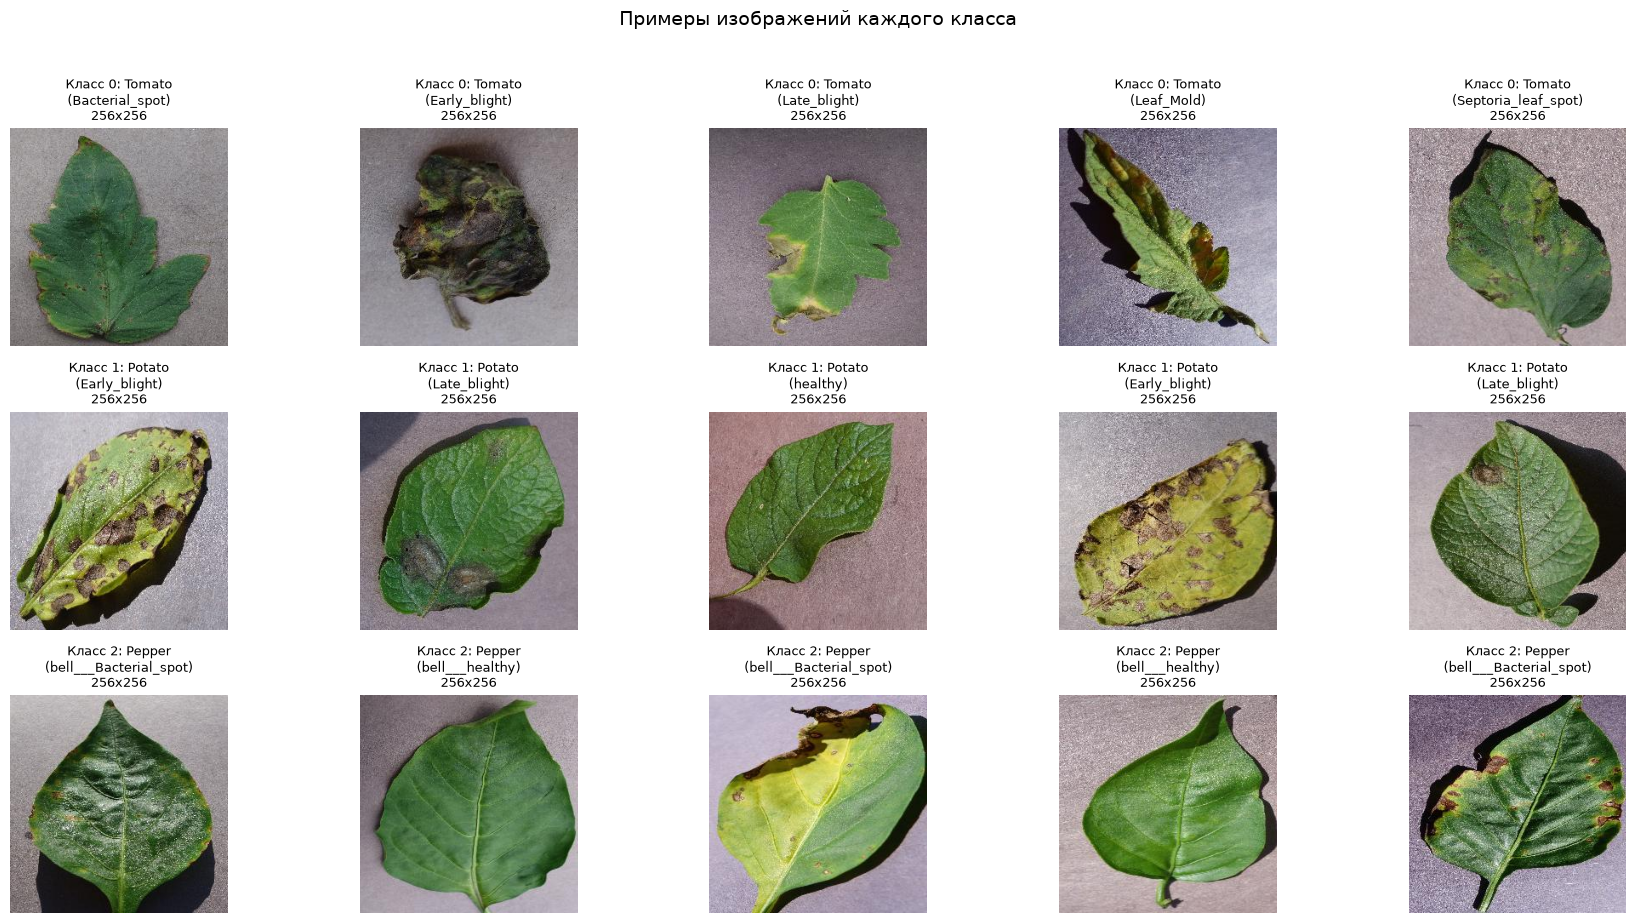

In [9]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(18, 9))

for row_idx, (class_id, class_name) in enumerate(CLASS_NAMES.items()):
    class_df = df[df["class_id"] == class_id]
    
    # Выбираем примеры из разных подклассов, если их несколько
    unique_subs = class_df["subfolder"].unique()
    sampled_rows = []
    for i in range(5):
        sub = unique_subs[i % len(unique_subs)]
        sample = class_df[class_df["subfolder"] == sub].sample(1, random_state=SEED + i)
        sampled_rows.append(sample.iloc[0])
    
    for col_idx, row in enumerate(sampled_rows):
        ax = axes[row_idx, col_idx]
        with Image.open(row["filepath"]) as img:
            ax.imshow(img)
        
        sub_short = row["subfolder"].replace(f"{class_name}___", "").replace(f"{class_name}__", "").replace(f"{class_name}_", "")
        ax.set_title(
            f"Класс {class_id}: {class_name}\n({sub_short})\n{row['width']}x{row['height']}",
            fontsize=9
        )
        ax.axis("off")

plt.suptitle("Примеры изображений каждого класса", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [10]:
ARTIFACTS_DIR = Path("./artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

n_before = len(df)
df_clean = df.drop_duplicates(subset=["md5"]).reset_index(drop=True)
n_removed = n_before - len(df_clean)
print(f"Удалено точных дубликатов (MD5): {n_removed}. Осталось уникальных изображений: {len(df_clean)}")

train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=SEED,
    stratify=df_clean["subfolder"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["subfolder"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df["filepath"]).isdisjoint(set(val_df["filepath"])), "Утечка filepath: train и val!"
assert set(train_df["filepath"]).isdisjoint(set(test_df["filepath"])), "Утечка filepath: train и test!"
assert set(val_df["filepath"]).isdisjoint(set(test_df["filepath"])), "Утечка filepath: val и test!"
assert set(train_df["md5"]).isdisjoint(set(val_df["md5"])), "Утечка MD5: train и val!"
assert set(train_df["md5"]).isdisjoint(set(test_df["md5"])), "Утечка MD5: train и test!"
assert set(val_df["md5"]).isdisjoint(set(test_df["md5"])), "Утечка MD5: val и test!"
print("Проверка на утечку данных пройдена: пересечений по путям и MD5 нет.")

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

splits_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
splits_path = ARTIFACTS_DIR / "dataset_splits_var0.csv"
splits_df.to_csv(splits_path, index=False)
print(f"Разбиение сохранено в: {splits_path}")

Удалено точных дубликатов (MD5): 14. Осталось уникальных изображений: 20624
Проверка на утечку данных пройдена: пересечений по путям и MD5 нет.
Разбиение сохранено в: artifacts/dataset_splits_var0.csv


In [11]:
total = len(df_clean)
print("\n=== РАЗМЕРЫ ВЫБОРОК ===")
for name, part in [("Train (70%)", train_df), ("Val (15%)", val_df), ("Test (15%)", test_df)]:
    print(f"{name:<12}: {len(part):>6} изображений ({len(part) / total * 100:.2f}%)")

print("\n=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===")
summary = pd.DataFrame({
    "Train_cnt": train_df["class_name"].value_counts(),
    "Train_%": (train_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Val_cnt": val_df["class_name"].value_counts(),
    "Val_%": (val_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Test_cnt": test_df["class_name"].value_counts(),
    "Test_%": (test_df["class_name"].value_counts(normalize=True) * 100).round(2),
})
print(summary)

# Расчёт весов классов СТРОГО по обучающей выборке (для борьбы с дисбалансом на Этапах 3 и 5)
# 1) Для бинарной классификации (только классы 0: Tomato и 1: Potato)
train_bin_df = train_df[train_df["class_id"].isin([0, 1])].reset_index(drop=True)
bin_classes = np.array([0, 1])
bin_weights = compute_class_weight(
    class_weight="balanced",
    classes=bin_classes,
    y=train_bin_df["class_id"].values
)
CLASS_WEIGHTS_BINARY = dict(zip(bin_classes, bin_weights))

# 2) Для трёхклассовой классификации (0: Tomato, 1: Potato, 2: Pepper)
multi_classes = np.array([0, 1, 2])
multi_weights = compute_class_weight(
    class_weight="balanced",
    classes=multi_classes,
    y=train_df["class_id"].values
)
CLASS_WEIGHTS_MULTI = dict(zip(multi_classes, multi_weights))

print("\nВеса классов для бинарной модели (по train):", {k: round(float(v), 4) for k, v in CLASS_WEIGHTS_BINARY.items()})
print("Веса классов для 3-классовой модели (по train):", {k: round(float(v), 4) for k, v in CLASS_WEIGHTS_MULTI.items()})


=== РАЗМЕРЫ ВЫБОРОК ===
Train (70%) :  14436 изображений (70.00%)
Val (15%)   :   3094 изображений (15.00%)
Test (15%)  :   3094 изображений (15.00%)

=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===
            Train_cnt  Train_%  Val_cnt  Val_%  Test_cnt  Test_%
class_name                                                      
Tomato          11197    77.56     2400  77.57      2400   77.57
Pepper           1733    12.00      371  11.99       371   11.99
Potato           1506    10.43      323  10.44       323   10.44

Веса классов для бинарной модели (по train): {np.int64(0): 0.5673, np.int64(1): 4.2175}
Веса классов для 3-классовой модели (по train): {np.int64(0): 0.4298, np.int64(1): 3.1952, np.int64(2): 2.7767}


In [12]:
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU активирован с memory_growth: {gpus}")
    except RuntimeError as e:
        print(f"GPU уже инициализирован, memory_growth не изменён: {e}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 64  
AUTOTUNE = tf.data.AUTOTUNE

def create_tf_dataset(dataframe: pd.DataFrame, img_size: tuple = IMG_SIZE, batch_size: int = BATCH_SIZE, shuffle: bool = False, cache: bool = False, preprocess_fn=None, seed: int = SEED) -> tf.data.Dataset:

    filepaths = dataframe["filepath"].values
    labels = dataframe["class_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    def load_and_preprocess(path, label):
        img_bytes = tf.io.read_file(path)
        img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method=tf.image.ResizeMethod.BILINEAR)
        img = tf.cast(img, tf.float32)

        if preprocess_fn is not None:
            img = preprocess_fn(img)
        else:
            img = img / 255.0  # [0; 1] для собственной CNN

        img.set_shape([img_size[0], img_size[1], 3])
        return img, label

    # Декодирование и ресайз распараллеливаются по ядрам CPU
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache:
        ds = ds.cache()  # Храним готовые тензоры в ОЗУ (~8.5 ГБ для train)

    if shuffle:
        # reshuffle_each_iteration=True заново перемешивает кэш на каждой эпохе
        ds = ds.shuffle(buffer_size=len(dataframe), seed=seed, reshuffle_each_iteration=True)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

# --- Формирование выборок для Этапа 3 (Бинарная CNN: классы 0 и 1) ---
val_bin_df = val_df[val_df["class_id"].isin([0, 1])].reset_index(drop=True)
test_bin_df = test_df[test_df["class_id"].isin([0, 1])].reset_index(drop=True)

train_ds_bin = create_tf_dataset(train_bin_df, shuffle=True, cache=True, preprocess_fn=None)
val_ds_bin = create_tf_dataset(val_bin_df, shuffle=False, cache=True, preprocess_fn=None)
test_ds_bin = create_tf_dataset(test_bin_df, shuffle=False, cache=False, preprocess_fn=None)

# Проверка формы и диапазона значений первого батча для собственной CNN
images_batch, labels_batch = next(iter(train_ds_bin))
print("\n=== ПРОВЕРКА БАТЧА ДЛЯ СОБСТВЕННОЙ CNN (БИНАРНАЯ) ===")
print("Форма тензора изображений:", images_batch.shape)
print("Тип данных:", images_batch.dtype)
print(f"Диапазон значений пикселей: [{images_batch.numpy().min():.3f}, {images_batch.numpy().max():.3f}]")
print("Метки в батче (уникальные):", np.unique(labels_batch.numpy()))
print(f"Размеры бинарных выборок -> train: {len(train_bin_df)}, val: {len(val_bin_df)}, test: {len(test_bin_df)}")

GPU активирован с memory_growth: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1795664434.880558    2372 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:05:00.0, compute capability: 8.9



=== ПРОВЕРКА БАТЧА ДЛЯ СОБСТВЕННОЙ CNN (БИНАРНАЯ) ===
Форма тензора изображений: (64, 224, 224, 3)
Тип данных: <dtype: 'float32'>
Диапазон значений пикселей: [0.000, 0.997]
Метки в батче (уникальные): [0 1]
Размеры бинарных выборок -> train: 12703, val: 2723, test: 2723


Model: "CNN_1_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,761 (98.07 MB)

 Trainable params: 25,709,761 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8378 - auc: 0.9152 - loss: 0.3894
Epoch 1: val_loss improved from None to 0.23499, saving model to artifacts/CNN-1_best.keras

Epoch 1: finished saving model to artifacts/CNN-1_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - accuracy: 0.8378 - auc: 0.9152 - loss: 0.3894 - val_accuracy: 0.9008 - val_auc: 0.9778 - val_loss: 0.2350 - learning_rate: 0.0010
Epoch 2/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9239 - auc: 0.9785 - loss: 0.1854
Epoch 2: val_loss improved from 0.23499 to 0.11127, saving model to artifacts/CNN-1_best.keras

Epoch 2: finished saving model to artifacts/CNN-1_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 19s 94ms/step - accuracy: 0.9238 - auc: 0.9786 - loss: 0.1852 - val_accuracy: 0.9614 - val_auc: 0.9812 - val_loss: 0.1113 - learning_rate: 0.0010
Epoch 3/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.9510 - auc: 0.9895 - loss: 0.1264
Epoch 3: val_loss improved from 0.11127 to 0.1

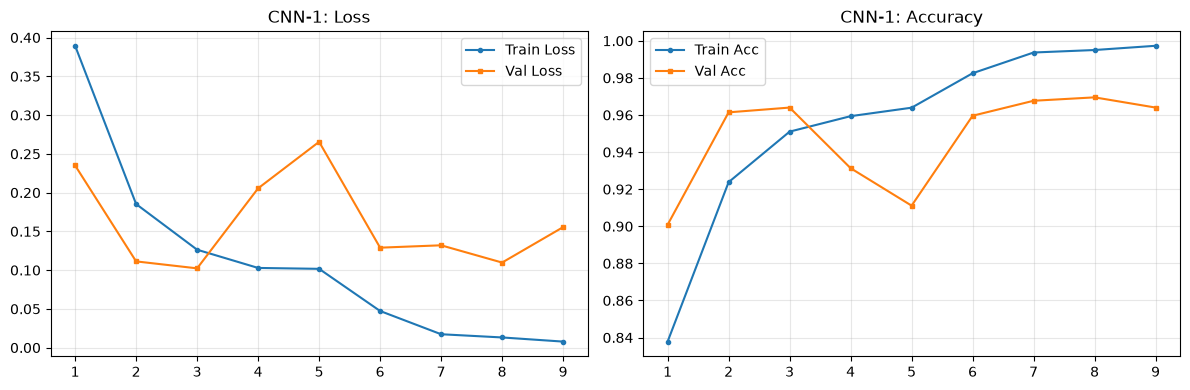


Результат CNN-1:
Эксперимент  Параметры                           Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761 2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001         9 (3)     168.3                0.951    0.964    0.1023         0.8261      0.8824  0.8533       0.9874


In [11]:
MAX_EPOCHS = 25
INPUT_SHAPE = (224, 224, 3)
# Общая функция запуска одного эксперимента с диагностикой (будем переиспользовать на каждом шаге)
def train_and_evaluate_val(model, exp_name: str, lr_init: float, opt_name: str, extra_info: dict):
    tf.keras.utils.set_random_seed(SEED)
    y_val_true = np.concatenate([y.numpy() for _, y in val_ds_bin], axis=0)

    ckpt_path = ARTIFACTS_DIR / f"{exp_name}_best.keras"
    cb_list = [
        callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=6, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
    ]

    t0 = time.perf_counter()
    history = model.fit(
        train_ds_bin,
        validation_data=val_ds_bin,
        epochs=MAX_EPOCHS,
        class_weight=CLASS_WEIGHTS_BINARY,
        callbacks=cb_list,
        verbose=1
    )
    elapsed = time.perf_counter() - t0

    hist = {k: [float(x) for x in v] for k, v in history.history.items()}
    with open(ARTIFACTS_DIR / f"{exp_name}_history.json", "w", encoding="utf-8") as f:
        json.dump(hist, f, indent=2)

    best_model = models.load_model(ckpt_path)
    val_loss = best_model.evaluate(val_ds_bin, verbose=0)[0]
    y_val_prob = best_model.predict(val_ds_bin, verbose=0).ravel()
    y_val_pred = (y_val_prob >= 0.5).astype(int)

    best_ep = int(np.argmin(hist["val_loss"])) + 1
    row = {
        "Эксперимент": exp_name,
        "Параметры": model.count_params(),
        **extra_info,
        "Оптимизатор": opt_name,
        "LR_init": lr_init,
        "Эпох (Лучшая)": f"{len(hist['loss'])} ({best_ep})",
        "Время, с": round(elapsed, 1),
        "Train Acc (best_ep)": round(hist["accuracy"][best_ep - 1], 4),
        "Val Acc": round(accuracy_score(y_val_true, y_val_pred), 4),
        "Val Loss": round(float(val_loss), 4),
        "Val Precision": round(precision_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val Recall": round(recall_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val F1": round(f1_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val_true, y_val_prob), 4),
    }

    # График обучения
    epochs_r = range(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_r, hist["loss"], label="Train Loss", marker="o", markersize=3)
    axes[0].plot(epochs_r, hist["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[0].set_title(f"{exp_name}: Loss")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs_r, hist["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[1].plot(epochs_r, hist["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[1].set_title(f"{exp_name}: Accuracy")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    del best_model
    tf.keras.backend.clear_session()
    gc.collect()
    return row, hist

# --- ШАГ 1: Базовая модель (CNN-1) ---
tf.keras.utils.set_random_seed(SEED)
cnn_1 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="CNN_1_Baseline")

cnn_1.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_1.summary()

all_val_results = []
all_histories = {}

res_1, hist_1 = train_and_evaluate_val(
    cnn_1, "CNN-1", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "2 Conv (32,64) + Flatten + Dense(128)", "Регуляризация": "Dropout 0.3"}
)
all_val_results.append(res_1)
all_histories["CNN-1"] = hist_1
print("\nРезультат CNN-1:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Анализ результатов CNN-1

* **Ловушка Accuracy vs F1 (`0.9640` vs `0.8533`):** Из-за дисбаланса (`Tomato` 88% / `Potato` 12%) константный прогноз дал бы 88% точности. Реальное качество на редком классе `Potato` отражает **F1 = 0.8533** (`Precision = 0.8261`, `Recall = 0.8824` — модель пропускает 11.8% картофеля и в 17.4% случаев путает с ним томаты). **Ориентир для отбора моделей:** `Val F1`, `Val Loss` и `Val ROC-AUC`.
* **Высокий Val ROC-AUC (`0.9874`):** Базовая 2-слойная сеть отлично разделяет классы по вероятностям, но при пороге `0.5` ошибается на граничных примерах (больных листьях). У датасета высокий потенциал.
* **Переобучение (`9 (3)` эпох и 25.7 млн параметров):** Лучший `Val Loss = 0.1023` достигнут уже на **3-й эпохе**, далее сработал `EarlyStopping`. Причина — слой `Flatten` раздул `Dense(128)` до **25.7 млн** параметров против ~19 тыс. в свертках (`2 Conv: 32, 64`). Вместо извлечения признаков сеть за 3 эпохи запомнила выборку.


Исходя из результатов CNN-1, у нас есть **две конкретные проблемы**:
    1. Раздутая «голова» (Flatten → 25.7 млн параметров) вызывает быстрое переобучение на 9-й эпохе.
    2. Слишком мелкая свёрточная часть (2 блока → обзор всего 10×10 пикселей) не даёт увидеть форму всего листа, из-за чего `Val F1` пока лишь 0.8533.

Model: "CNN_2_Deep_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.5793 - auc: 0.6930 - loss: 0.6280
Epoch 1: val_loss improved from None to 0.35952, saving model to artifacts/CNN-2_best.keras

Epoch 1: finished saving model to artifacts/CNN-2_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - accuracy: 0.5793 - auc: 0.6930 - loss: 0.6280 - val_accuracy: 0.8795 - val_auc: 0.8326 - val_loss: 0.3595 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.7948 - auc: 0.8868 - loss: 0.4232
Epoch 2: val_loss improved from 0.35952 to 0.27781, saving model to artifacts/CNN-2_best.keras

Epoch 2: finished saving model to artifacts/CNN-2_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - accuracy: 0.7948 - auc: 0.8868 - loss: 0.4232 - val_accuracy: 0.8939 - val_auc: 0.9201 - val_loss: 0.2778 - learning_rate: 0.0010
Epoch 3/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.8239 - auc: 0.9122 - loss: 0.3752
Epoch 3: val_loss did not improve from 0.2

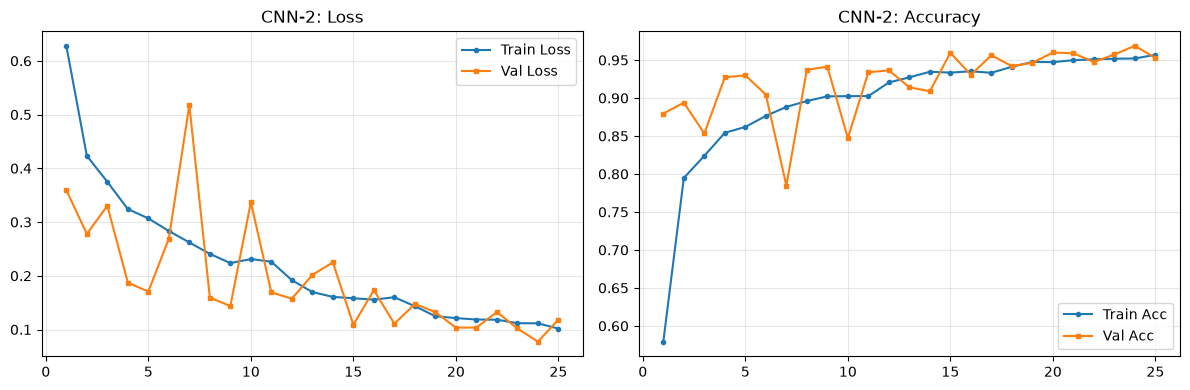


Сравнение CNN-1 и CNN-2:
Эксперимент  Параметры                           Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761 2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001         9 (3)     168.3               0.9510   0.9640    0.1023         0.8261      0.8824  0.8533       0.9874
      CNN-2     109889 3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (24)     514.8               0.9521   0.9688    0.0775         0.8251      0.9350  0.8766       0.9937


In [12]:
tf.keras.utils.set_random_seed(SEED)

cnn_2 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    # Блок 1: базовые границы и цвета (224 -> 112)
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Блок 2: текстуры и края листа (112 -> 56)
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Блок 3: более сложные фрагменты формы и жилки (56 -> 28)
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Усредняем каждую из 128 карт признаков в 1 число (вместо Flatten!)
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="CNN_2_Deep_GAP")

cnn_2.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_2.summary()

res_2, hist_2 = train_and_evaluate_val(
    cnn_2, "CNN-2", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "3 Conv (32,64,128) + GAP + Dense(128)", "Регуляризация": "Нет (GAP)"}
)
all_val_results.append(res_2)
all_histories["CNN-2"] = hist_2

print("\nСравнение CNN-1 и CNN-2:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Сравнительный анализ CNN-1 и CNN-2

Замена `Flatten` на `GlobalAveragePooling2D` (GAP) и добавление третьего свёрточного слоя (`128` фильтров) полностью решили проблему раннего переобучения и улучшили все целевые метрики.

* **Радикальное сжатие модели (в 234 раза):** Число параметров сократилось с **25.7 млн** до **109.9 тыс.** Вместо запоминания обучающей выборки сеть начала извлекать обобщающие признаки формы и текстуры листьев.
* **Стабильное обучение без переобучения (`25 (24)` эпох):** Лучший `Val Loss` снизился с `0.1023` до **0.0775** на **24-й эпохе** (против 3-й у CNN-1). На графиках видно, что после 15-й эпохи кривые `Val Loss` и `Val Acc` стабилизировались и перестали испытывать резкие скачки (как на 7-й и 10-й эпохах), а `Train` и `Val` метрики сошлись без разрыва.
* **Рост качества на редком классе `Potato`:**
  * **Val Recall** вырос с `0.8824` до **0.9350** — модель стала пропускать почти в 2 раза меньше картофеля (**6.5%** вместо 11.8%).
  * **Val F1** вырос с `0.8533` до **0.8766** при практически неизменном `Precision` (`0.8251`).
  * **Val ROC-AUC** достиг **0.9937** (против `0.9874`), подтверждая отличную разделимость классов.


Model: "CNN_3_BatchNorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,945 (433.38 KB)

 Trainable params: 110,241 (430.63 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.8775 - auc: 0.9556 - loss: 0.2753
Epoch 1: val_loss improved from None to 0.56196, saving model to artifacts/CNN-3_best.keras

Epoch 1: finished saving model to artifacts/CNN-3_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 29s 134ms/step - accuracy: 0.8775 - auc: 0.9556 - loss: 0.2753 - val_accuracy: 0.8814 - val_auc: 0.7129 - val_loss: 0.5620 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.9184 - auc: 0.9807 - loss: 0.1790
Epoch 2: val_loss improved from 0.56196 to 0.48608, saving model to artifacts/CNN-3_best.keras

Epoch 2: finished saving model to artifacts/CNN-3_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 24s 118ms/step - accuracy: 0.9184 - auc: 0.9807 - loss: 0.1790 - val_accuracy: 0.8575 - val_auc: 0.7189 - val_loss: 0.4861 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.9379 - auc: 0.9860 - loss: 0.1465
Epoch 3: val_loss improved from 0.48608 to

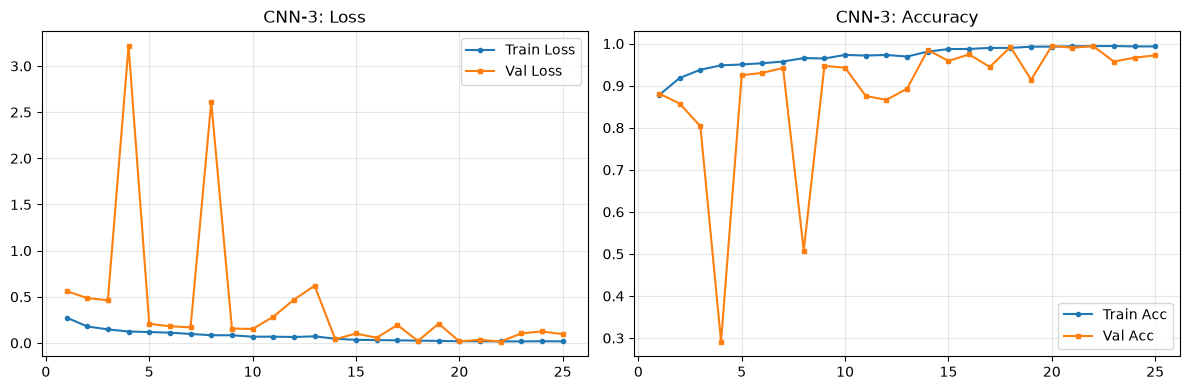


Сравнение CNN-1, CNN-2 и CNN-3:
Эксперимент  Параметры                                Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001         9 (3)     168.3               0.9510   0.9640    0.1023         0.8261      0.8824  0.8533       0.9874
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (24)     514.8               0.9521   0.9688    0.0775         0.8251      0.9350  0.8766       0.9937
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm        Adam    0.001       25 (19)     594.3               0.9897   0.9949    0.0212         0.9843      0.9721  0.9782       0.9996
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm        Adam    0.001       25 (22) 

In [16]:
tf.keras.utils.set_random_seed(SEED)

cnn_3 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    # Блок 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Блок 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Блок 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dense(1, activation="sigmoid")
], name="CNN_3_BatchNorm")

cnn_3.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_3.summary()

res_3, hist_3 = train_and_evaluate_val(
    cnn_3, "CNN-3", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "3 Conv (32,64,128) + BN + GAP + Dense(128)", "Регуляризация": "BatchNorm"}
)
all_val_results.append(res_3)
all_histories["CNN-3"] = hist_3

print("\nСравнение CNN-1, CNN-2 и CNN-3:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Сравнительный анализ: прорыв в CNN-3 с добавлением BatchNorm

Добавление слоёв `BatchNormalization` практически не увеличило размер модели (**110.9 тыс.** против **109.9 тыс.** параметров у CNN-2), но обеспечило качественный скачок по всем ключевым метрикам.

* **Кардинальный рост качества на редком классе `Potato`:**
  * **Val F1** вырос с `0.8766` до **0.9782** (+10.2 п.п.).
  * **Val Precision** поднялся с `0.8251` до **0.9843** — доля ложных срабатываний на томатах снизилась с 17.5% до **1.6%**.
  * **Val Recall** вырос с `0.9350` до **0.9721** — модель пропускает лишь **2.8%** изображений картофеля.
* **Почти идеальная разделимость классов:** `Val Loss` снизился почти в 4 раза (с `0.0775` до **0.0212**), а **Val ROC-AUC** достиг **0.9996**.
* **Динамика обучения (по графикам):** В первой половине обучения (эпохи 1–13) наблюдались резкие выбросы `Val Loss` (до `3.2` на 4-й эпохе и `2.6` на 8-й) с просадками `Val Acc`, что характерно для настройки статистик `BatchNorm` при `LR = 0.001`. После **14-й эпохи** кривые полностью стабилизировались, пик качества достигнут на **19-й эпохе** (`25 (19)`), признаки переобучения отсутствуют.



=== СВОДНАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ (ВАЛИДАЦИОННАЯ ВЫБОРКА) ===
Эксперимент  Параметры                                Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001         9 (3)     168.3               0.9510   0.9640    0.1023         0.8261      0.8824  0.8533       0.9874
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (24)     514.8               0.9521   0.9688    0.0775         0.8251      0.9350  0.8766       0.9937
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm        Adam    0.001       25 (19)     594.3               0.9897   0.9949    0.0212         0.9843      0.9721  0.9782       0.9996
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm      

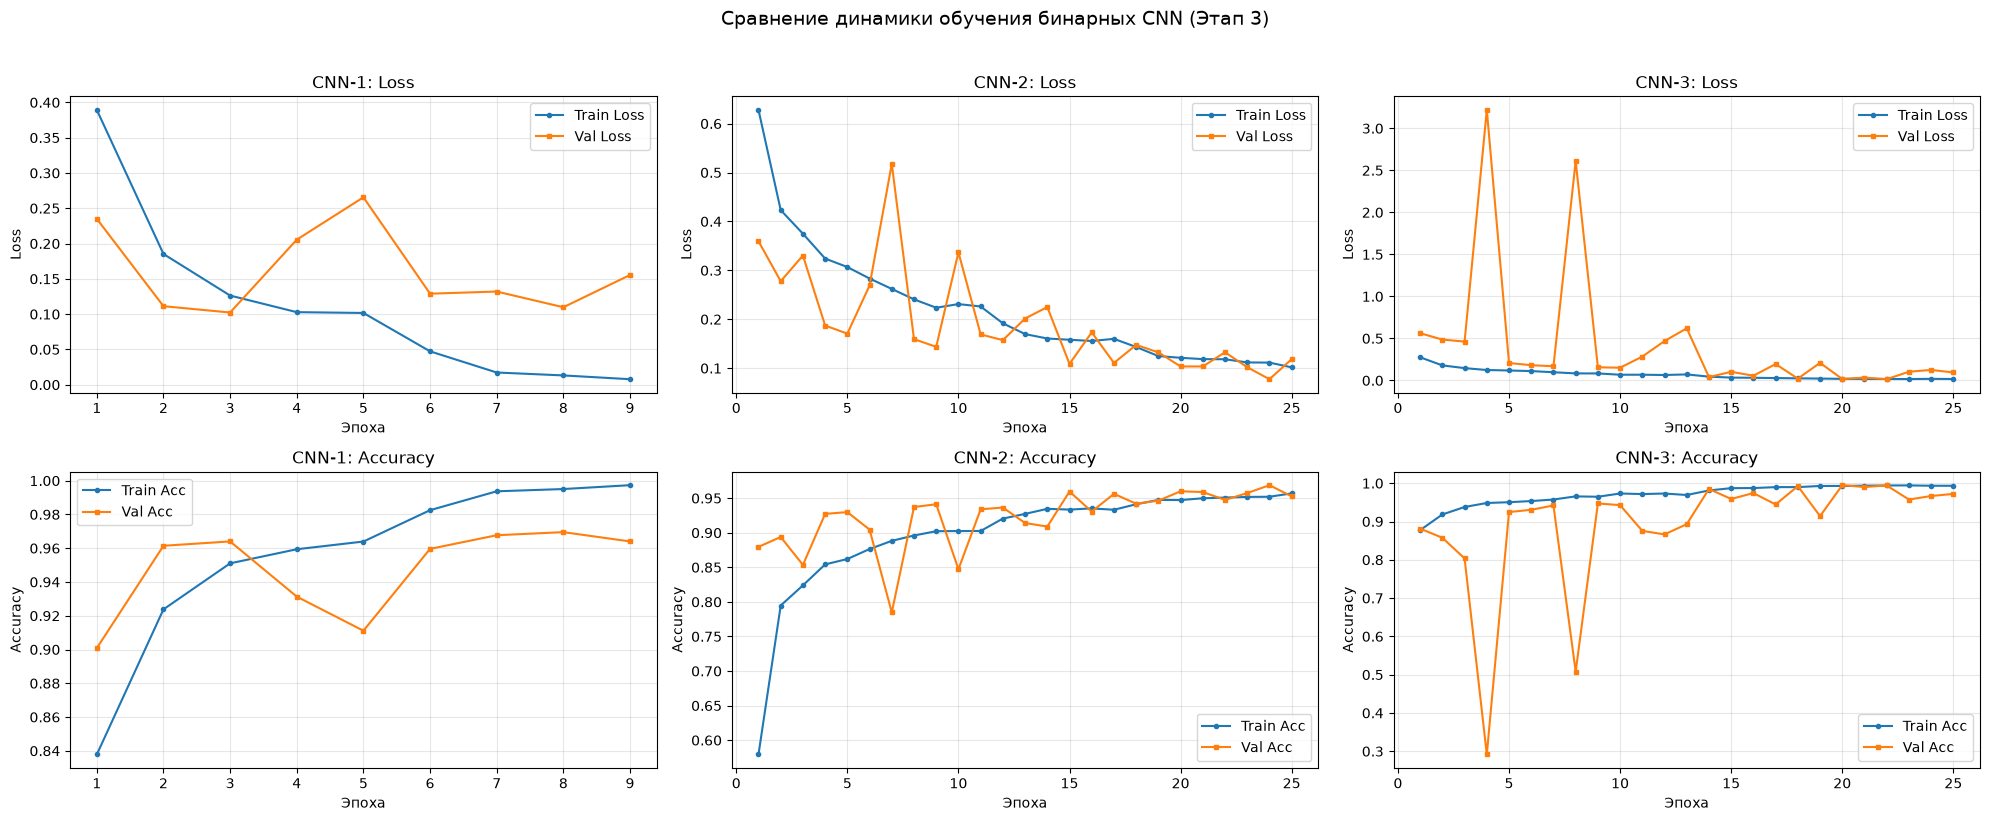

In [17]:
experiments_order = ['CNN-1', 'CNN-2', 'CNN-3']
results_bin_df = pd.DataFrame(all_val_results)
results_bin_df.to_csv(ARTIFACTS_DIR / "stage3_binary_cnn_val_results.csv", index=False)

print("\n=== СВОДНАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ (ВАЛИДАЦИОННАЯ ВЫБОРКА) ===")
display_cols = [
    "Эксперимент", "Параметры", "Архитектура", "Регуляризация","Оптимизатор", "LR_init",
    "Эпох (Лучшая)", "Время, с", "Train Acc (best_ep)","Val Acc","Val Loss", 
    "Val Precision", "Val Recall", "Val F1", "Val ROC-AUC"
]
print(results_bin_df[display_cols].to_string(index=False))

# 2. Графики Loss и Accuracy по эпохам для всех моделей
fig, axes = plt.subplots(2, len(experiments_order), figsize=(20, 8), sharex=False)

for idx, exp_name in enumerate(experiments_order):
    h = all_histories[exp_name]
    epochs_range = range(1, len(h["loss"]) + 1)

    # Loss
    axes[0, idx].plot(epochs_range, h["loss"], label="Train Loss", marker="o", markersize=3)
    axes[0, idx].plot(epochs_range, h["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[0, idx].set_title(f"{exp_name}: Loss")
    axes[0, idx].set_xlabel("Эпоха")
    axes[0, idx].set_ylabel("Loss")
    axes[0, idx].grid(True, alpha=0.3)
    axes[0, idx].legend()

    # Accuracy
    axes[1, idx].plot(epochs_range, h["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[1, idx].plot(epochs_range, h["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[1, idx].set_title(f"{exp_name}: Accuracy")
    axes[1, idx].set_xlabel("Эпоха")
    axes[1, idx].set_ylabel("Accuracy")
    axes[1, idx].grid(True, alpha=0.3)
    axes[1, idx].legend()

plt.suptitle("Сравнение динамики обучения бинарных CNN (Этап 3)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage3_binary_cnn_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Итоговый вывод по серии экспериментов (CNN-1/CNN-2/CNN-3)

В ходе поэтапной оптимизации архитектуры свёрточной нейронной сети удалось одновременно **сократить размер модели в 232 раза** и **повысить качество классификации редкого класса `Potato` по метрике F1 с `0.8533` до `0.9782`**.

1. **Устранение переобучения и сжатие модели (CNN-1 -> CNN-2):**
   Замена громоздкого слоя `Flatten` на `GlobalAveragePooling2D` (GAP) и углубление свёрточной части сократили число параметров с **25.7 млн** до **109.9 тыс.** Это остановило запоминание обучающей выборки на 3-й эпохе и позволило сети стабильно обучаться до 24-й эпохи, подняв `Val Recall` до `0.9350`.
2. **Стабилизация признаков и прорыв по качеству (CNN-2 -> CNN-3):**
   Внедрение `BatchNormalization` (при росте параметров всего на ~1 тыс.) устранило проблему низкой точности на граничных примерах. Модель **CNN-3** показала лучший баланс ошибок: `Val Precision = 0.9843` и `Val Recall = 0.9721` (`Val F1 = 0.9782`, `Val Loss = 0.0212`, `Val ROC-AUC = 0.9996`), полностью нивелировав влияние сильного дисбаланса классов (88% / 12%).

> В качестве финальной модели выбирается **CNN-3 (веса с 19-й эпохи)** как наиболее лёгкая, устойчивая к переобучению и высокоточная архитектура.


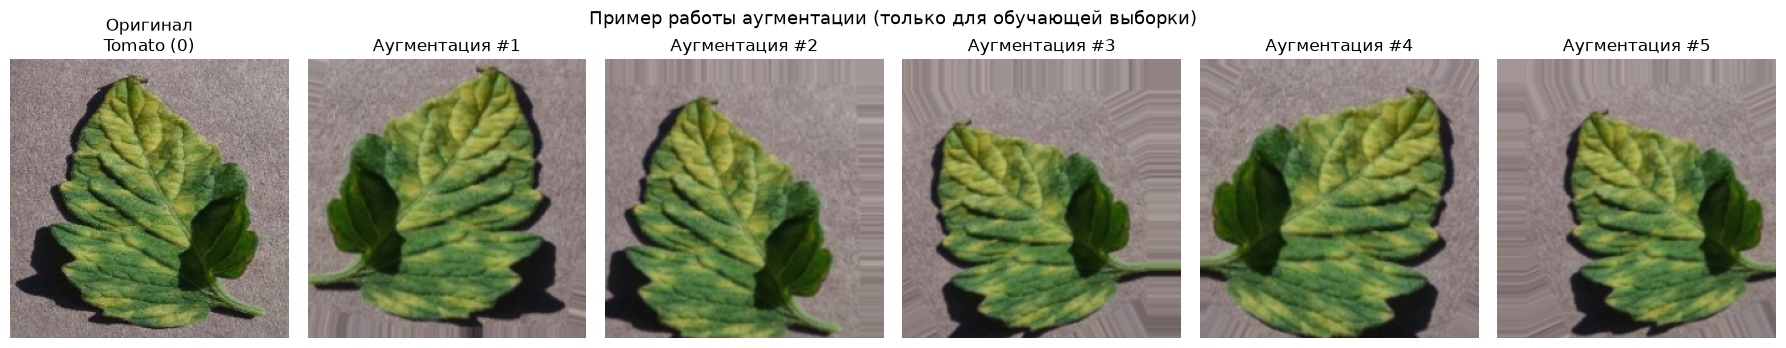

In [18]:
# Блок аугментации (0 обучаемых параметров)
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.08, fill_mode="nearest", seed=SEED),
    layers.RandomZoom(height_factor=(-0.10, 0.10), fill_mode="nearest", seed=SEED),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08, fill_mode="nearest", seed=SEED),
], name="Plant_Augmentation")

# Визуализация: 1 исходное фото и 5 вариантов аугментации (сохраняем картинку для отчёта)
sample_batch_imgs, sample_batch_labels = next(iter(train_ds_bin))
sample_img = sample_batch_imgs[0:1]  # берём 1 картинку формы (1, 224, 224, 3)
sample_cls = "Potato (1)" if int(sample_batch_labels[0]) == 1 else "Tomato (0)"

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(sample_img[0].numpy())
axes[0].set_title(f"Оригинал\n{sample_cls}")
axes[0].axis("off")

for i in range(1, 6):
    aug_img = data_augmentation(sample_img, training=True)
    axes[i].imshow(np.clip(aug_img[0].numpy(), 0.0, 1.0))
    axes[i].set_title(f"Аугментация #{i}")
    axes[i].axis("off")

plt.suptitle("Пример работы аугментации (только для обучающей выборки)", fontsize=13)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage4_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

Epoch 1/25


W0000 00:00:1795621287.122669    5741 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.8760 - auc: 0.9554 - loss: 0.2754
Epoch 1: val_loss improved from None to 0.35093, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 1: finished saving model to artifacts/CNN-3+Aug_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 65s 312ms/step - accuracy: 0.8760 - auc: 0.9554 - loss: 0.2754 - val_accuracy: 0.8869 - val_auc: 0.8014 - val_loss: 0.3509 - learning_rate: 0.0010
Epoch 2/25


W0000 00:00:1795621352.519034    5741 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.9147 - auc: 0.9764 - loss: 0.1949
Epoch 2: val_loss did not improve from 0.35093
199/199 ━━━━━━━━━━━━━━━━━━━━ 52s 262ms/step - accuracy: 0.9147 - auc: 0.9764 - loss: 0.1949 - val_accuracy: 0.8876 - val_auc: 0.8108 - val_loss: 0.4368 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.9259 - auc: 0.9830 - loss: 0.1647
Epoch 3: val_loss improved from 0.35093 to 0.19677, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 3: finished saving model to artifacts/CNN-3+Aug_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 45s 226ms/step - accuracy: 0.9259 - auc: 0.9830 - loss: 0.1647 - val_accuracy: 0.9174 - val_auc: 0.9644 - val_loss: 0.1968 - learning_rate: 0.0010
Epoch 4/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.9401 - auc: 0.9885 - loss: 0.1389
Epoch 4: val_loss did not improve from 0.19677
199/199 ━━━━━━━━━━━━━━━━━━━━ 46s 232ms/step - accuracy: 0.9401 - auc: 0.9885 - loss: 0.1389 - 

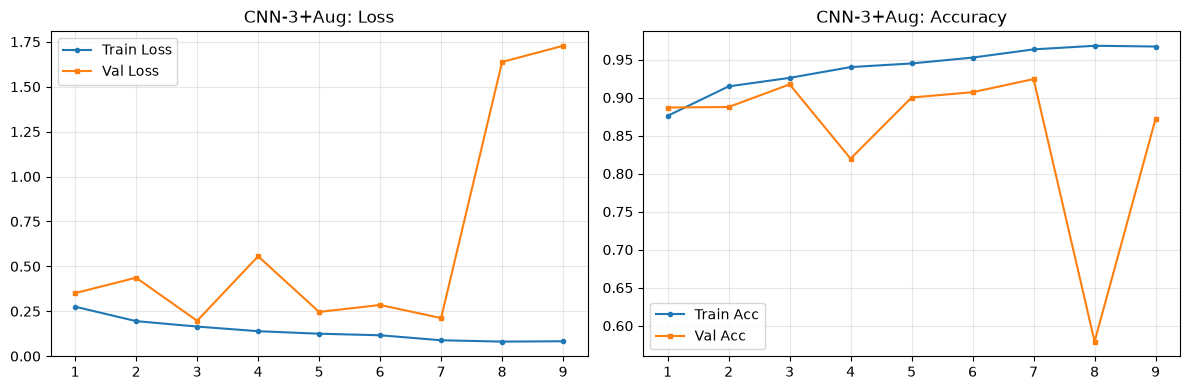


=== СРАВНЕНИЕ НА ВАЛИДАЦИИ (ВЫБОР ЛУЧШЕЙ МОДЕЛИ) ===
Эксперимент  Параметры                                Архитектура   Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)     Dropout 0.3        Adam    0.001         9 (3)     168.3               0.9510   0.9640    0.1023         0.8261      0.8824  0.8533       0.9874
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)       Нет (GAP)        Adam    0.001       25 (24)     514.8               0.9521   0.9688    0.0775         0.8251      0.9350  0.8766       0.9937
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)       BatchNorm        Adam    0.001       25 (19)     594.3               0.9897   0.9949    0.0212         0.9843      0.9721  0.9782       0.9996
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)       BatchNorm     

In [20]:
cnn3_template= models.clone_model(cnn_3)

cnn_3_aug = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),
    data_augmentation,
    cnn3_template
], name="CNN_3_Augmented")

cnn_3_aug.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

# 3. Запускаем обучение на тех же train_ds_bin / val_ds_bin
res_aug, hist_aug = train_and_evaluate_val(
    cnn_3_aug, "CNN-3+Aug", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "3 Conv (32,64,128) + BN + GAP + Dense(128)", "Регуляризация": "BatchNorm + Aug"}
)

all_val_results.append(res_aug)
all_histories["CNN-3+Aug"] = hist_aug

val_comp_df = pd.DataFrame(all_val_results)
print("\n=== СРАВНЕНИЕ НА ВАЛИДАЦИИ (ВЫБОР ЛУЧШЕЙ МОДЕЛИ) ===")
print(val_comp_df.to_string(index=False))

Разрыв (Train Acc - Val Acc) на лучшей эпохе ДО аугментации ("CNN-3"): -0.0000
Разрыв (Train Acc - Val Acc) на лучшей эпохе ПОСЛЕ аугментации ("CNN-3+Aug"): +0.0086


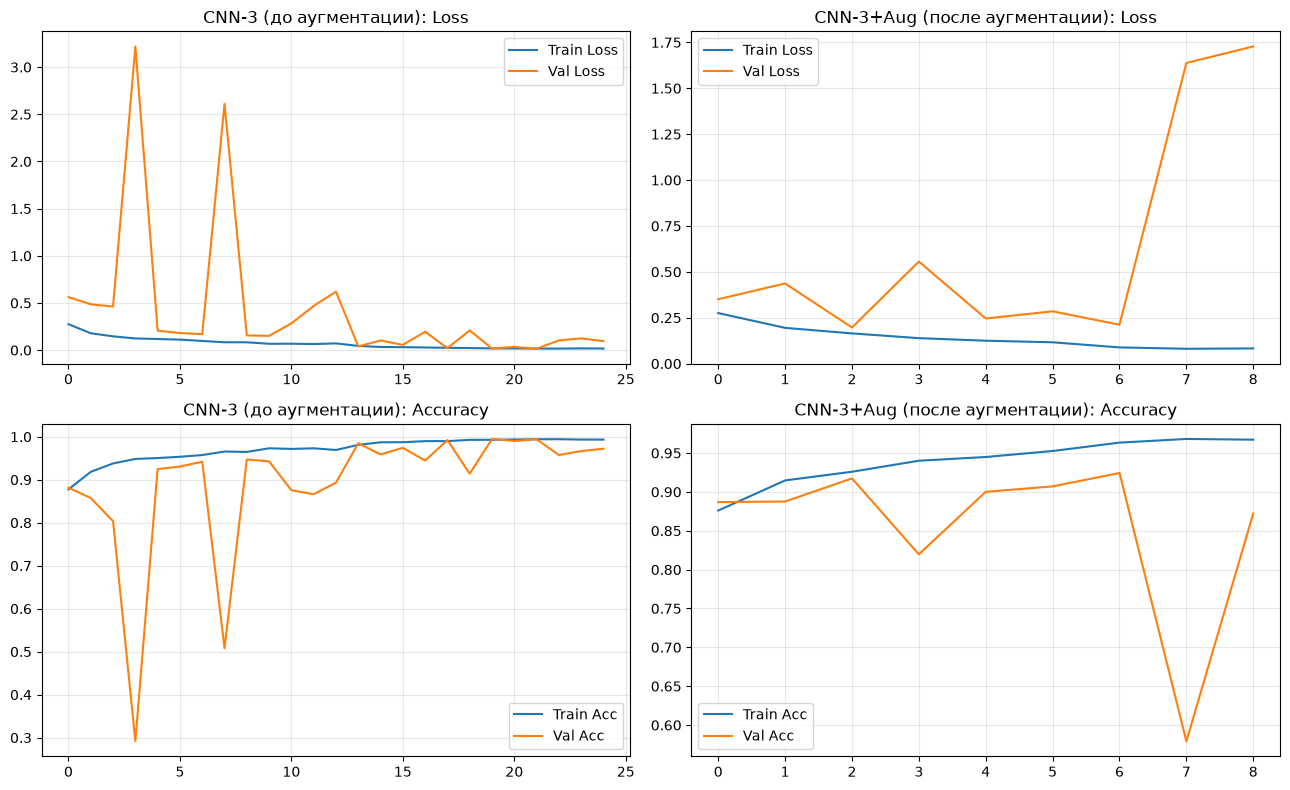

In [21]:
h_before = all_histories["CNN-3"]
h_after = all_histories["CNN-3+Aug"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Loss ДО и ПОСЛЕ
axes[0, 0].plot(h_before["loss"], label="Train Loss")
axes[0, 0].plot(h_before["val_loss"], label="Val Loss")
axes[0, 0].set_title(f"{"CNN-3"} (до аугментации): Loss")
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(h_after["loss"], label="Train Loss")
axes[0, 1].plot(h_after["val_loss"], label="Val Loss")
axes[0, 1].set_title(f"{"CNN-3+Aug"} (после аугментации): Loss")
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

# Accuracy ДО и ПОСЛЕ
axes[1, 0].plot(h_before["accuracy"], label="Train Acc")
axes[1, 0].plot(h_before["val_accuracy"], label="Val Acc")
axes[1, 0].set_title(f"{"CNN-3"} (до аугментации): Accuracy")
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(h_after["accuracy"], label="Train Acc")
axes[1, 1].plot(h_after["val_accuracy"], label="Val Acc")
axes[1, 1].set_title(f"{"CNN-3+Aug"} (после аугментации): Accuracy")
axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

# Расчёт разрыва (Train Acc - Val Acc) на лучшей эпохе
best_ep_b = int(np.argmin(h_before["val_loss"]))
gap_before = h_before["accuracy"][best_ep_b] - h_before["val_accuracy"][best_ep_b]

best_ep_a = int(np.argmin(h_after["val_loss"]))
gap_after = h_after["accuracy"][best_ep_a] - h_after["val_accuracy"][best_ep_a]

print(f"Разрыв (Train Acc - Val Acc) на лучшей эпохе ДО аугментации (\"CNN-3\"): {gap_before:+.4f}")
print(f"Разрыв (Train Acc - Val Acc) на лучшей эпохе ПОСЛЕ аугментации (\"CNN-3+Aug\"): {gap_after:+.4f}")

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage4_before_after_aug_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Анализ эксперимента CNN-3+Aug (негативный эффект аугментации)

Добавление аугментации данных (`BatchNorm + Aug`) привело к резкой деградации качества по всем метрикам — модель показала результат хуже базовой **CNN-1** и остановилась уже на **9-й эпохе** (`9 (3)`).

* **Обвал качества на редком классе (`Val F1 = 0.7082`):** По сравнению с лучшей `CNN-3` (`F1 = 0.9782`) метрика упала на **27 п.п.** Основной удар пришёлся по **Val Precision (0.6094)** — почти **39% листьев**, которые модель отнесла к картофелю, оказались томатами. `Val Loss` вырос почти в 10 раз (до **0.1968**).
* **Нестабильность валидации и взрыв Loss (по графикам):** Пока `Train Loss` плавно снижался до `0.08`, кривая `Val Loss` испытывала сильные колебания и на **8-й эпохе** резко взлетела до **~1.64–1.73** с провалом `Val Acc` до **~0.58**.
* **Причины провала:**
  1. **Искажение диагностических признаков:** Агрессивные геометрические или цветовые аугментации (сдвиги оттенков, кропы, контраст) разрушают мелкую текстуру и цветовые пятна болезней листьев, по которым сеть отличает культуры.
  2. **Конфликт `BatchNorm` и аугментации:** Статистики батчей (`mean`/`var`), накопленные на сильно искажённых обучающих картинках, перестают соответствовать «чистой» валидационной выборке, что и вызывает резкие выбросы `Val Loss`.
  3. **Недостаток ёмкости:** Лёгкой сети на **110.9 тыс.** параметров не хватает выразительной способности, чтобы за короткое время адаптироваться к усложнённому распределению данных.

---

### Итоговый выбор лучшей модели

По совокупности метрик валидации абсолютным лидером остаётся **CNN-3 (без аугментации)**:
* **Повторный запуск CNN-3 (`25 (22)`)** подтвердил воспроизводимость результата: минимальный `Val Loss = 0.0147`, наивысший `Val ROC-AUC = 0.9997` и идеальный баланс `Precision = Recall = F1 = 0.9752` (против `0.9782` на 19-й эпохе первого прогона).
* **Финальный кандидат:** архитектура **CNN-3** (`3 Conv + BN + GAP + Dense(128)`), сочетающая минимальный размер (~111 тыс. параметров) и максимальную точность на дисбалансном датасете.


In [13]:
for var_name in ["train_ds_bin", "val_ds_bin"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()

# 2. Создаём 3-классовые выборки (0: Tomato, 1: Potato, 2: Pepper) со строгой MobileNetV2-предобработкой
train_ds_multi = create_tf_dataset(
    train_df, shuffle=True, cache=True, preprocess_fn=mobilenet_preprocess
)
val_ds_multi = create_tf_dataset(
    val_df, shuffle=False, cache=True, preprocess_fn=mobilenet_preprocess
)
test_ds_multi = create_tf_dataset(
    test_df, shuffle=False, cache=False, preprocess_fn=mobilenet_preprocess
)

# Быстрая проверка диапазона пикселей (для MobileNetV2 должно быть примерно [-1.0, 1.0]) и меток {0, 1, 2}
xb, yb = next(iter(train_ds_multi))
print(f"Форма батча: {xb.shape}, диапазон пикселей: [{xb.numpy().min():.2f}, {xb.numpy().max():.2f}]")
print("Уникальные метки в батче:", np.unique(yb.numpy()))
print(f"Размеры выборок -> train: {len(train_df)}, val: {len(val_df)}, test: {len(test_df)}")

Форма батча: (64, 224, 224, 3), диапазон пикселей: [-1.00, 0.99]
Уникальные метки в батче: [0 1 2]
Размеры выборок -> train: 14436, val: 3094, test: 3094


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Режим A | Всего параметров: 2,261,827 | Обучаемых: 3,843
Epoch 1/15


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795664536.398269    2372 service.cc:154] XLA service 0x2e46fbf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795664536.398303    2372 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4060, Compute Capability 8.9 (Driver: 13.4.0[617.14.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1795664536.441314    2372 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795664536.959284    2372 cuda_dnn.cc:442] Loaded cuDNN version 92600
W0000 00:00:1795664538.651804    3097 cuda_timer.cc:88] Delay ke

  2/226 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - accuracy: 0.2891 - loss: 1.0431 

I0000 00:00:1795664546.409565    2372 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1795664546.491516    2372 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1795664534663274757 in buffer 'PrefetchDataset/_21' sat unconsumed for 11.8236 seconds!


225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9332 - loss: 0.1889

I0000 00:00:1795664559.530016    3858 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_2', 8 bytes spill stores, 8 bytes spill loads

W0000 00:00:1795664561.732908    3859 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9333 - loss: 0.1887

W0000 00:00:1795664575.282549    4650 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.10413, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 1: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 42s 136ms/step - accuracy: 0.9333 - loss: 0.1887 - val_accuracy: 0.9703 - val_loss: 0.1041 - learning_rate: 0.0010
Epoch 2/15
  2/226 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.9844 - loss: 0.1011 

W0000 00:00:1795664577.016482    2372 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9796 - loss: 0.0631
Epoch 2: val_loss improved from 0.10413 to 0.07261, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 2: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 17s 75ms/step - accuracy: 0.9796 - loss: 0.0630 - val_accuracy: 0.9754 - val_loss: 0.0726 - learning_rate: 0.0010
Epoch 3/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9851 - loss: 0.0445
Epoch 3: val_loss improved from 0.07261 to 0.06144, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 3: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9851 - loss: 0.0449 - val_accuracy: 0.9800 - val_loss: 0.0614 - learning_rate: 0.0010
Epoch 4/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9862 - loss: 0.0363
Epoch 4: val_loss improved from 0.06144 to 0.04901, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoc

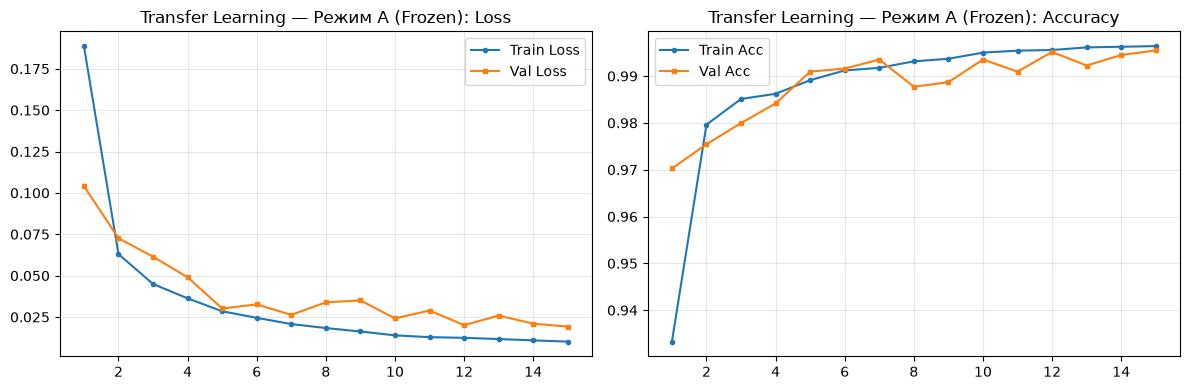

In [15]:
tf.keras.utils.set_random_seed(SEED)
INPUT_SHAPE = (224, 224, 3)

# 1. Загружаем предобученный backbone без верхней классификационной части
base_model = MobileNetV2(
    input_shape=INPUT_SHAPE,
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Замораживаем все слои основы

# 2. Собираем модель с помощью Functional API
inputs = layers.Input(shape=INPUT_SHAPE)
x = base_model(inputs, training=False)  # training=False важно для заморозки статистик BN внутри основы
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="head_dropout")(x)
outputs = layers.Dense(3, activation="softmax", name="head_output")(x)

model_tl_frozen = models.Model(inputs, outputs, name="MobileNetV2_ModeA_Frozen")

model_tl_frozen.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params_A = np.sum([np.prod(w.shape) for w in model_tl_frozen.trainable_weights])
print(f"Режим A | Всего параметров: {model_tl_frozen.count_params():,} | Обучаемых: {trainable_params_A:,}")

ckpt_A = ARTIFACTS_DIR / "TL_ModeA_Frozen_best.keras"
cb_A = [
    callbacks.ModelCheckpoint(str(ckpt_A), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

t0 = time.perf_counter()
hist_A = model_tl_frozen.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=15,
    class_weight=CLASS_WEIGHTS_MULTI,
    callbacks=cb_A,
    verbose=1
)
time_A = time.perf_counter() - t0

hist_A_dict = {k: [float(v) for v in vals] for k, vals in hist_A.history.items()}
with open(ARTIFACTS_DIR / "TL_ModeA_history.json", "w", encoding="utf-8") as f:
    json.dump(hist_A_dict, f, indent=2)

# Отдельные графики Loss и Accuracy для Режима A (требование Этапа 6)
ep_A = range(1, len(hist_A_dict["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep_A, hist_A_dict["loss"], label="Train Loss", marker="o", markersize=3)
axes[0].plot(ep_A, hist_A_dict["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[0].set_title("Transfer Learning — Режим A (Frozen): Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_A, hist_A_dict["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[1].plot(ep_A, hist_A_dict["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[1].set_title("Transfer Learning — Режим A (Frozen): Accuracy"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage5_modeA_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Режим B | Разморожено слоёв основы: 30 (без BN) | Обучаемых параметров: 1,514,563
Epoch 1/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9887 - loss: 0.0234
Epoch 1: val_loss improved from None to 0.02291, saving model to artifacts/TL_ModeB_FineTuned_best.keras

Epoch 1: finished saving model to artifacts/TL_ModeB_FineTuned_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - accuracy: 0.9887 - loss: 0.0234 - val_accuracy: 0.9913 - val_loss: 0.0229 - learning_rate: 3.0000e-05
Epoch 2/15
  1/226 ━━━━━━━━━━━━━━━━━━━━ 44s 199ms/step - accuracy: 1.0000 - loss: 0.0047

W0000 00:00:1795664872.163976    2372 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9942 - loss: 0.0103
Epoch 2: val_loss did not improve from 0.02291
226/226 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.9943 - loss: 0.0103 - val_accuracy: 0.9913 - val_loss: 0.0245 - learning_rate: 3.0000e-05
Epoch 3/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9974 - loss: 0.0056
Epoch 3: val_loss improved from 0.02291 to 0.00494, saving model to artifacts/TL_ModeB_FineTuned_best.keras

Epoch 3: finished saving model to artifacts/TL_ModeB_FineTuned_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 16s 71ms/step - accuracy: 0.9974 - loss: 0.0056 - val_accuracy: 0.9987 - val_loss: 0.0049 - learning_rate: 3.0000e-05
Epoch 4/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9997 - loss: 8.7787e-04
Epoch 4: val_loss did not improve from 0.00494
226/226 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.9997 - loss: 8.7818e-04 - val_accuracy: 0.9984 - val_loss: 0.0061 - learning_rate: 3.0000e-05
Epoch 5/15
225/226 ━━━━━

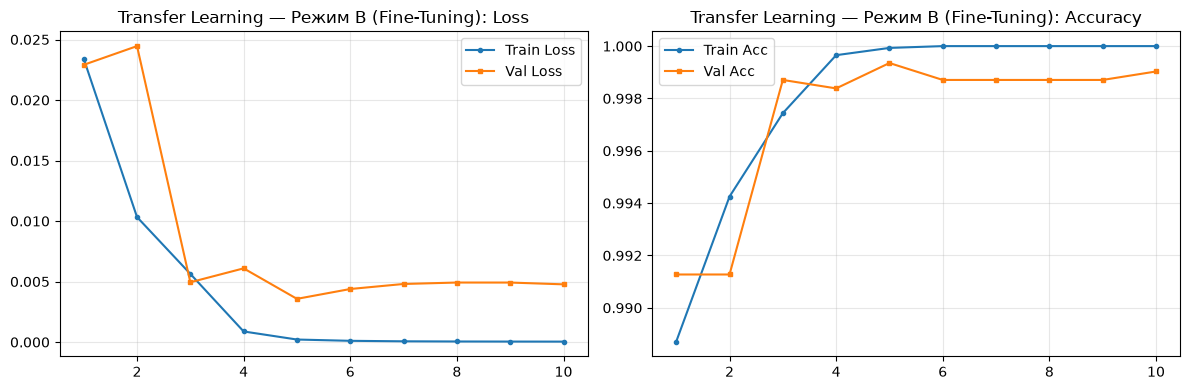

In [16]:
# 1. Загружаем лучшую модель Режима A, чтобы адаптировать её дальше
model_tl_ft = models.load_model(ckpt_A)

# Находим вложенный backbone MobileNetV2
backbone_layer = [l for l in model_tl_ft.layers if isinstance(l, tf.keras.Model)][0]
backbone_layer.trainable = True

# Замораживаем все слои, кроме последних 30, а также держим замороженными все BatchNorm
FINE_TUNE_AT = len(backbone_layer.layers) - 30
for i, layer in enumerate(backbone_layer.layers):
    if i < FINE_TUNE_AT or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# 2. Обязательная повторная компиляция после изменения trainable с малой скоростью обучения
model_tl_ft.compile(
    optimizer=optimizers.Adam(learning_rate=3e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params_B = np.sum([np.prod(w.shape) for w in model_tl_ft.trainable_weights])
print(f"Режим B | Разморожено слоёв основы: 30 (без BN) | Обучаемых параметров: {trainable_params_B:,}")

ckpt_B = ARTIFACTS_DIR / "TL_ModeB_FineTuned_best.keras"
cb_B = [
    callbacks.ModelCheckpoint(str(ckpt_B), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

t0 = time.perf_counter()
hist_B = model_tl_ft.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=15,
    class_weight=CLASS_WEIGHTS_MULTI,
    callbacks=cb_B,
    verbose=1
)
time_B = time.perf_counter() - t0

hist_B_dict = {k: [float(v) for v in vals] for k, vals in hist_B.history.items()}
with open(ARTIFACTS_DIR / "TL_ModeB_history.json", "w", encoding="utf-8") as f:
    json.dump(hist_B_dict, f, indent=2)

# Отдельные графики Loss и Accuracy для Режима B (требование Этапа 6)
ep_B = range(1, len(hist_B_dict["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep_B, hist_B_dict["loss"], label="Train Loss", marker="o", markersize=3)
axes[0].plot(ep_B, hist_B_dict["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[0].set_title("Transfer Learning — Режим B (Fine-Tuning): Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_B, hist_B_dict["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[1].plot(ep_B, hist_B_dict["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[1].set_title("Transfer Learning — Режим B (Fine-Tuning): Accuracy"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage5_modeB_curves.png", dpi=150, bbox_inches="tight")
plt.show()

=== СРАВНЕНИЕ РЕЖИМОВ TRANSFER LEARNING НА ВАЛИДАЦИИ ===
                    Режим      LR  Эпох  Время, с   Loss  Accuracy  Macro Precision  Macro Recall  Macro F1
   A: Замороженная основа 0.00100    15     254.8 0.0192    0.9955           0.9889        0.9945    0.9917
B: Fine-tuning (30 слоёв) 0.00003    10     178.1 0.0036    0.9994           0.9988        0.9988    0.9988

Лучший режим по валидации: B: Fine-tuning (30 слоёв) -> сохранено в artifacts/best_multiclass_tl.keras


W0000 00:00:1795665887.045521    2372 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1795665892.438609    2372 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1795665903.408199    2372 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size



=== ИТОГОВЫЕ МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ (3 КЛАССА) ===
                    Режим   Loss  Accuracy  Macro Precision  Macro Recall  Macro F1
   A: Замороженная основа 0.0297    0.9900           0.9780        0.9854    0.9816
B: Fine-tuning (30 слоёв) 0.0137    0.9955           0.9947        0.9893    0.9919

--- Подробный отчёт по классам на TEST: Режим A (Frozen) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9958    0.9921    0.9939      2400
  Potato (1)     0.9515    0.9721    0.9617       323
  Pepper (2)     0.9866    0.9919    0.9892       371

    accuracy                         0.9900      3094
   macro avg     0.9780    0.9854    0.9816      3094
weighted avg     0.9901    0.9900    0.9900      3094

--- Подробный отчёт по классам на TEST: Режим B (Fine-Tuning) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9958    0.9983    0.9971      2400
  Potato (1)     0.9937    0.9721    0.9828       323
  Pepper (2)     0.

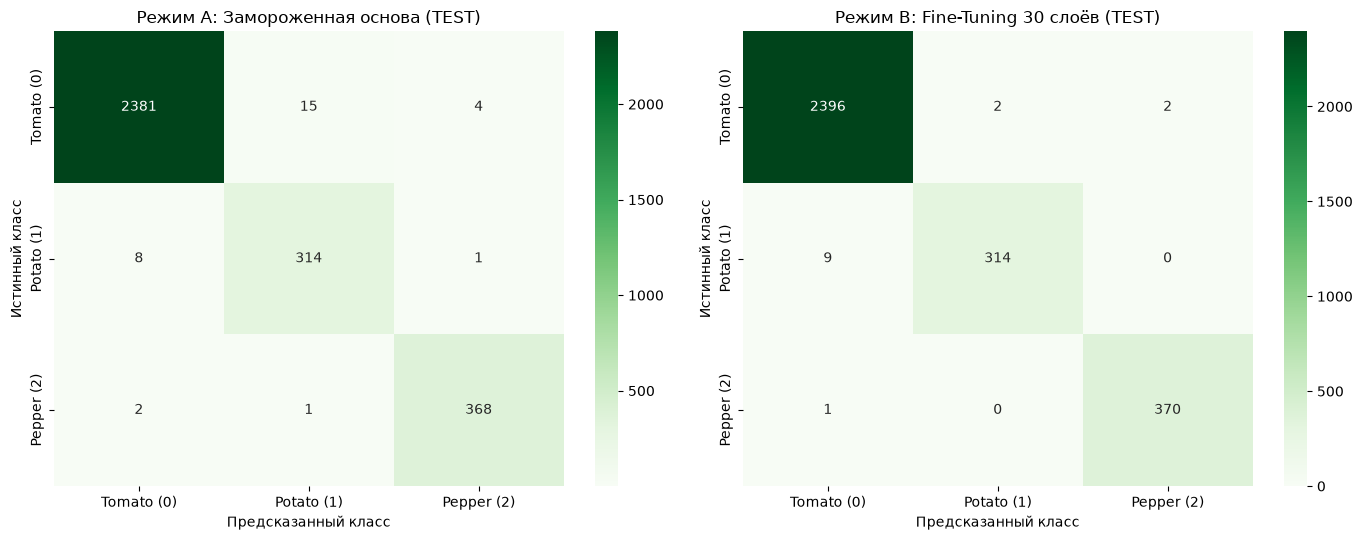

In [20]:
CLASS_LABELS = ["Tomato (0)", "Potato (1)", "Pepper (2)"]
y_val_multi_true = np.concatenate([y.numpy() for _, y in val_ds_multi], axis=0)
y_test_multi_true = np.concatenate([y.numpy() for _, y in test_ds_multi], axis=0)

def evaluate_multiclass(ckpt_path, ds, y_true):
    m = models.load_model(ckpt_path)
    loss = m.evaluate(ds, verbose=0)[0]
    y_prob = m.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    metrics_dict = {
        "Loss": round(float(loss), 4),
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro Precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    }
    return metrics_dict, y_pred

# 1. Сравнение на ВАЛИДАЦИИ и выбор лучшей 3-классовой модели
val_A, _ = evaluate_multiclass(ckpt_A, val_ds_multi, y_val_multi_true)
val_B, _ = evaluate_multiclass(ckpt_B, val_ds_multi, y_val_multi_true)

val_tl_df = pd.DataFrame([
    {"Режим": "A: Замороженная основа", "LR": 1e-3, "Эпох": len(hist_A_dict["loss"]), "Время, с": round(time_A, 1), **val_A},
    {"Режим": "B: Fine-tuning (30 слоёв)", "LR": 3e-5, "Эпох": len(hist_B_dict["loss"]), "Время, с": round(time_B, 1), **val_B},
])
print("=== СРАВНЕНИЕ РЕЖИМОВ TRANSFER LEARNING НА ВАЛИДАЦИИ ===")
print(val_tl_df.to_string(index=False))

best_tl_idx = val_tl_df["Macro F1"].idxmax()
best_ckpt_src = ckpt_A if best_tl_idx == 0 else ckpt_B
shutil.copyfile(best_ckpt_src, ARTIFACTS_DIR / "best_multiclass_tl.keras")
print(f"\nЛучший режим по валидации: {val_tl_df.loc[best_tl_idx, 'Режим']} -> сохранено в artifacts/best_multiclass_tl.keras")

# 2. Итоговая оценка обоих режимов на ОТЛОЖЕННОЙ ТЕСТОВОЙ ВЫБОРКЕ
test_A, y_pred_test_A = evaluate_multiclass(ckpt_A, test_ds_multi, y_test_multi_true)
test_B, y_pred_test_B = evaluate_multiclass(ckpt_B, test_ds_multi, y_test_multi_true)

test_tl_df = pd.DataFrame([
    {"Режим": "A: Замороженная основа", **test_A},
    {"Режим": "B: Fine-tuning (30 слоёв)", **test_B},
])
test_tl_df.to_csv(ARTIFACTS_DIR / "stage5_6_multiclass_test_comparison.csv", index=False)

print("\n=== ИТОГОВЫЕ МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ (3 КЛАССА) ===")
print(test_tl_df.to_string(index=False))

print("\n--- Подробный отчёт по классам на TEST: Режим A (Frozen) ---")
print(classification_report(y_test_multi_true, y_pred_test_A, target_names=CLASS_LABELS, digits=4))

print("--- Подробный отчёт по классам на TEST: Режим B (Fine-Tuning) ---")
print(classification_report(y_test_multi_true, y_pred_test_B, target_names=CLASS_LABELS, digits=4))

# 3. Матрицы ошибок на TEST для обоих режимов
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, y_p, title in [
    (axes[0], y_pred_test_A, "Режим A: Замороженная основа (TEST)"),
    (axes[1], y_pred_test_B, "Режим B: Fine-Tuning 30 слоёв (TEST)")
]:
    cm = confusion_matrix(y_test_multi_true, y_p)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens",
        xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage6_multiclass_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show() 

In [22]:
ARTIFACTS_DIR = Path("./artifacts")
splits_df = pd.read_csv(ARTIFACTS_DIR / "dataset_splits_var0.csv")

val_df = splits_df[splits_df["split"] == "val"].reset_index(drop=True)
test_df = splits_df[splits_df["split"] == "test"].reset_index(drop=True)
val_bin_df = val_df[val_df["class_id"].isin([0, 1])].reset_index(drop=True)
test_bin_df = test_df[test_df["class_id"].isin([0, 1])].reset_index(drop=True)

def make_ds(df, preprocess_fn=None):
    ds = tf.data.Dataset.from_tensor_slices((df["filepath"].values, df["class_id"].values.astype(np.int32)))
    def _load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img = tf.cast(tf.image.resize(img, (224, 224)), tf.float32)
        img = preprocess_fn(img) if preprocess_fn else (img / 255.0)
        img.set_shape([224, 224, 3])
        return img, label
    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE)

val_ds_bin = make_ds(val_bin_df)
test_ds_bin = make_ds(test_bin_df)
val_ds_multi = make_ds(val_df, mobilenet_preprocess)
test_ds_multi = make_ds(test_df, mobilenet_preprocess)


=== 1. ЛУЧШАЯ БИНАРНАЯ МОДЕЛЬ НА TEST: CNN-3 ===
Положительный класс: 1 (Potato) | Отрицательный класс: 0 (Tomato)
Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC
 CNN-3    0.9941     0.9582  0.9938    0.9757   0.9999


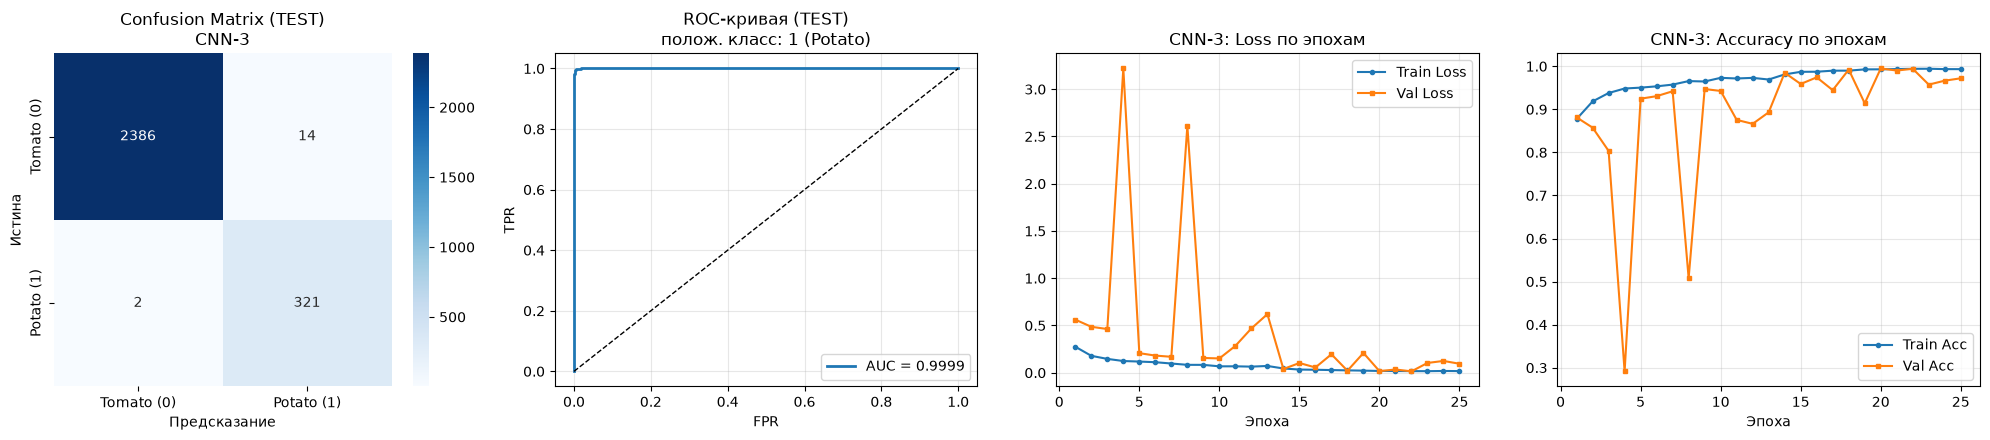

In [24]:
y_val_bin = val_bin_df["class_id"].values
y_test_bin = test_bin_df["class_id"].values

best_bin_name, best_bin_score = None, (-1.0, float("inf"))
for name in ["CNN-1", "CNN-2", "CNN-3", "CNN-3+Aug"]:
    ckpt = ARTIFACTS_DIR / f"{name}_best.keras"
    if not ckpt.exists():
        continue
    m = models.load_model(ckpt)
    v_loss = m.evaluate(val_ds_bin, verbose=0, return_dict=True)["loss"]
    v_pred = (m.predict(val_ds_bin, verbose=0).ravel() >= 0.5).astype(int)
    v_f1 = f1_score(y_val_bin, v_pred, pos_label=1, zero_division=0)
    if (v_f1, -v_loss) > (best_bin_score[0], -best_bin_score[1]):
        best_bin_score = (v_f1, v_loss)
        best_bin_name = name
    del m; tf.keras.backend.clear_session(); gc.collect()

shutil.copyfile(ARTIFACTS_DIR / f"{best_bin_name}_best.keras", ARTIFACTS_DIR / "best_binary_cnn.keras")
best_bin_model = models.load_model(ARTIFACTS_DIR / "best_binary_cnn.keras")
bin_test_prob = best_bin_model.predict(test_ds_bin, verbose=0).ravel()
bin_test_pred = (bin_test_prob >= 0.5).astype(int)
del best_bin_model; tf.keras.backend.clear_session(); gc.collect()

print(f"=== 1. ЛУЧШАЯ БИНАРНАЯ МОДЕЛЬ НА TEST: {best_bin_name} ===")
print("Положительный класс: 1 (Potato) | Отрицательный класс: 0 (Tomato)")
print(pd.DataFrame([{
    "Модель": best_bin_name,
    "Accuracy": round(accuracy_score(y_test_bin, bin_test_pred), 4),
    "Precision": round(precision_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "Recall": round(recall_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "F1-score": round(f1_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test_bin, bin_test_prob), 4),
}]).to_string(index=False))

# Графики для бинарной модели: Confusion Matrix, ROC-кривая, Loss и Accuracy по эпохам
with open(ARTIFACTS_DIR / f"{best_bin_name}_history.json", "r", encoding="utf-8") as f:
    h_bin = json.load(f)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.heatmap(
    confusion_matrix(y_test_bin, bin_test_pred), annot=True, fmt="d", cmap="Blues",
    xticklabels=["Tomato (0)", "Potato (1)"], yticklabels=["Tomato (0)", "Potato (1)"], ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix (TEST)\n{best_bin_name}")
axes[0].set_xlabel("Предсказание"); axes[0].set_ylabel("Истина")

fpr, tpr, _ = roc_curve(y_test_bin, bin_test_prob)
auc_val = roc_auc_score(y_test_bin, bin_test_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc_val:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC-кривая (TEST)\nполож. класс: 1 (Potato)")
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].legend(loc="lower right"); axes[1].grid(True, alpha=0.3)

ep = range(1, len(h_bin["loss"]) + 1)
axes[2].plot(ep, h_bin["loss"], label="Train Loss", marker="o", markersize=3)
axes[2].plot(ep, h_bin["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[2].set_title(f"{best_bin_name}: Loss по эпохам")
axes[2].set_xlabel("Эпоха"); axes[2].legend(); axes[2].grid(True, alpha=0.3)

axes[3].plot(ep, h_bin["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[3].plot(ep, h_bin["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[3].set_title(f"{best_bin_name}: Accuracy по эпохам")
axes[3].set_xlabel("Эпоха"); axes[3].legend(); axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage6_binary_final.png", dpi=150, bbox_inches="tight")
plt.show()



=== 2. ТРЁХКЛАССОВЫЕ МОДЕЛИ НА TEST (Лучшая по Val: Режим B (Fine-Tuning)) ===
               Модель  Accuracy  Macro Precision  Macro Recall  Macro F1
     Режим A (Frozen)    0.9900           0.9780        0.9854    0.9816
Режим B (Fine-Tuning)    0.9955           0.9947        0.9893    0.9919

--- Метрики по каждому классу и macro-avg на TEST: Режим A (Frozen) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9958    0.9921    0.9939      2400
  Potato (1)     0.9515    0.9721    0.9617       323
  Pepper (2)     0.9866    0.9919    0.9892       371

    accuracy                         0.9900      3094
   macro avg     0.9780    0.9854    0.9816      3094
weighted avg     0.9901    0.9900    0.9900      3094


--- Метрики по каждому классу и macro-avg на TEST: Режим B (Fine-Tuning) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9958    0.9983    0.9971      2400
  Potato (1)     0.9937    0.9721    0.9828       323
  Pepp

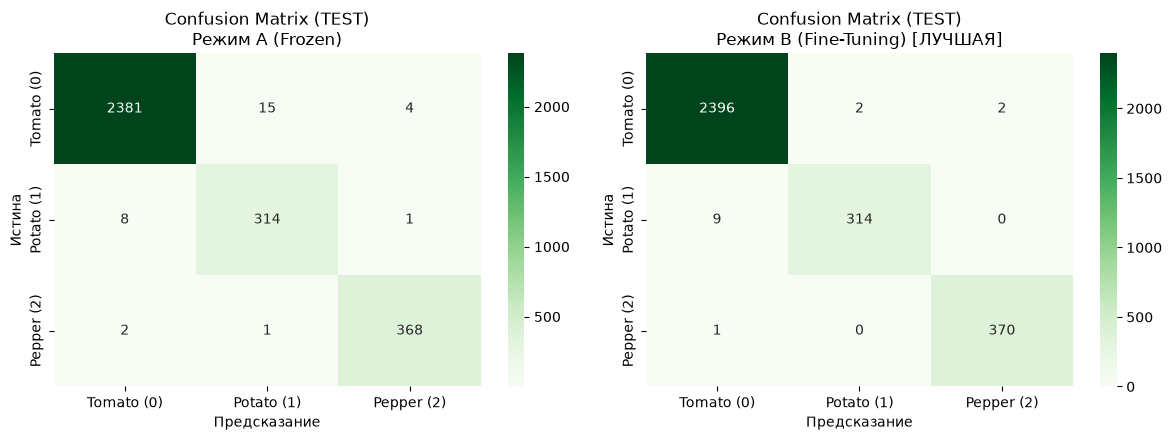

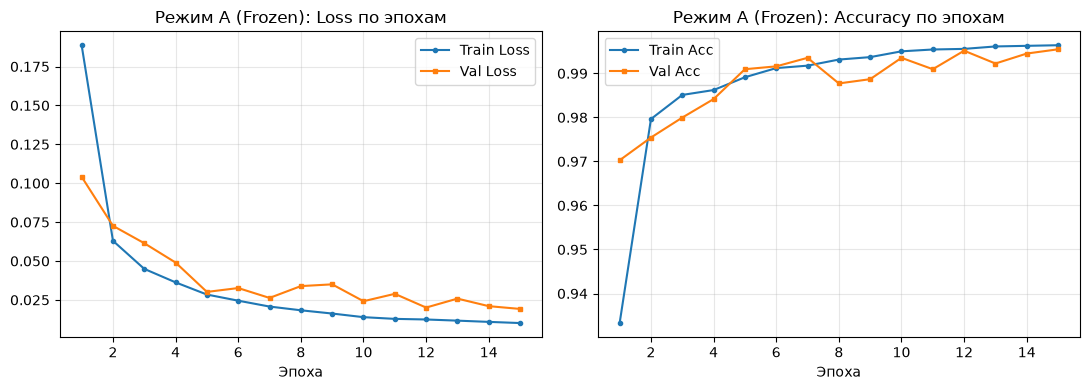

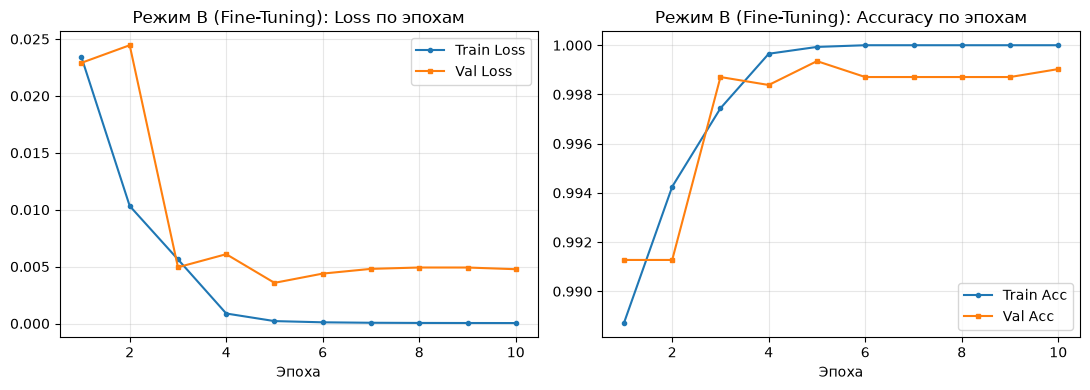

In [25]:
CLASS_LABELS = ["Tomato (0)", "Potato (1)", "Pepper (2)"]
y_val_multi = val_df["class_id"].values
y_test_multi = test_df["class_id"].values

tl_configs = [
    ("Режим A (Frozen)", "TL_ModeA_Frozen_best.keras", "TL_ModeA_history.json"),
    ("Режим B (Fine-Tuning)", "TL_ModeB_FineTuned_best.keras", "TL_ModeB_history.json"),
]

tl_summary = []
tl_preds = {}
best_tl_name, best_tl_f1 = None, -1.0

for title, ckpt_name, _ in tl_configs:
    ckpt = ARTIFACTS_DIR / ckpt_name
    if not ckpt.exists():
        continue
    m = models.load_model(ckpt)
    v_pred = np.argmax(m.predict(val_ds_multi, verbose=0), axis=1)
    v_macro_f1 = f1_score(y_val_multi, v_pred, average="macro", zero_division=0)
    if v_macro_f1 > best_tl_f1:
        best_tl_f1 = v_macro_f1
        best_tl_name = title
        shutil.copyfile(ckpt, ARTIFACTS_DIR / "best_multiclass_tl.keras")

    t_pred = np.argmax(m.predict(test_ds_multi, verbose=0), axis=1)
    tl_preds[title] = t_pred
    tl_summary.append({
        "Модель": title,
        "Accuracy": round(accuracy_score(y_test_multi, t_pred), 4),
        "Macro Precision": round(precision_score(y_test_multi, t_pred, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_test_multi, t_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_test_multi, t_pred, average="macro", zero_division=0), 4),
    })
    del m; tf.keras.backend.clear_session(); gc.collect()

print(f"\n=== 2. ТРЁХКЛАССОВЫЕ МОДЕЛИ НА TEST (Лучшая по Val: {best_tl_name}) ===")
print(pd.DataFrame(tl_summary).to_string(index=False))

for title, t_pred in tl_preds.items():
    print(f"\n--- Метрики по каждому классу и macro-avg на TEST: {title} ---")
    print(classification_report(y_test_multi, t_pred, target_names=CLASS_LABELS, digits=4))

# Матрицы ошибок на TEST (отдельно для Режима A и B)
fig, axes = plt.subplots(1, len(tl_preds), figsize=(12, 4.5))
if len(tl_preds) == 1:
    axes = [axes]
for ax, (title, t_pred) in zip(axes, tl_preds.items()):
    sns.heatmap(
        confusion_matrix(y_test_multi, t_pred), annot=True, fmt="d", cmap="Greens",
        xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=ax
    )
    tag = " [ЛУЧШАЯ]" if title == best_tl_name else ""
    ax.set_title(f"Confusion Matrix (TEST)\n{title}{tag}")
    ax.set_xlabel("Предсказание"); ax.set_ylabel("Истина")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage6_multiclass_cm.png", dpi=150, bbox_inches="tight")
plt.show()

# Раздельные графики Loss и Accuracy по эпохам для Режима A и Режима B
for title, _, hist_name in tl_configs:
    hist_path = ARTIFACTS_DIR / hist_name
    if not hist_path.exists():
        continue
    with open(hist_path, "r", encoding="utf-8") as f:
        h = json.load(f)
    ep = range(1, len(h["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(ep, h["loss"], label="Train Loss", marker="o", markersize=3)
    axes[0].plot(ep, h["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[0].set_title(f"{title}: Loss по эпохам")
    axes[0].set_xlabel("Эпоха"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(ep, h["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[1].plot(ep, h["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[1].set_title(f"{title}: Accuracy по эпохам")
    axes[1].set_xlabel("Эпоха"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    safe_tag = "modeA" if "ModeA" in hist_name else "modeB"
    plt.savefig(ARTIFACTS_DIR / f"stage6_tl_{safe_tag}_curves.png", dpi=150, bbox_inches="tight")
    plt.show()